# 2-11 증권사 리포트 흐름 — 누가 언제 무슨 리포트를 냈고, 목표주가는 어디쯤인가

**질문 예시:** "삼성전자 최근 반년 증권사 리포트 정리해줘", "증권사 목표주가 평균이랑 지금 주가 차이는?", "최신 리포트 첫 장 요약해줘", "요즘 리포트가 가장 많이 나오는 종목은?"

CHECK API에는 증권사 리포트·목표주가·투자의견이 없습니다(CHECK `1_기업펀더멘털` README: "목표주가·투자의견은 제공되지 않습니다").
DeepSearch는 **리포트 원문 PDF**와 **증권사별 목표주가·투자의견**을 함께 줘서, 새로 만든 시나리오입니다.

| 단계 | DeepSearch 함수 |
|---|---|
| 리포트 목록(증권사·제목·PDF) | `DocumentSearch(["research"],["company"], "securities.symbol:005930")` |
| 목표주가·투자의견 | `SearchTargetPrices(KRX:005930, …)` |
| 주가 | `GetStockPrices` |
| 리포트가 많이 나온 종목 | `DocumentAggregation(["research"],["company"], "*", "securities.symbol:30")` |
| PDF 본문 | 리포트 링크(`ddi-cdn.deepsearch.com/…pdf`)를 받아 PyMuPDF로 텍스트 추출 |

**종목 지정은 `securities.symbol:6자리코드`로 하세요.** 리서치 문서의 종목 이름은 `에스케이하이닉스`·`현대자동차`처럼 공식명이 섞여 있어
`securities.name:SK하이닉스`로는 일부만 잡힙니다(2026-08~11 SK하이닉스: 이름 2건 vs 코드 19건).

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/deepsearch/blob/main/scenarios/2_disclosure_news/11_analyst_reports.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `DEEPSEARCH_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib

In [2]:
# ── DeepSearch 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 이름 DEEPSEARCH_API_KEY 로 키를 넣고 "노트북 액세스"를 켜세요.
#        키는 "아이디:비밀번호" 형식이든 base64 문자열이든 됩니다. 키 값은 출력하지 않습니다.
# 로컬: 환경변수 DEEPSEARCH_API_KEY / API_KEY 또는 상위 폴더의 .env 를 읽습니다.
import base64, json, os, sys, time
from datetime import date, datetime, timedelta

import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
API_URL = "https://api.deepsearch.com/v1/compute"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def _norm_key(k):
    k = k.strip().strip('"').strip("'")
    return base64.b64encode(k.encode()).decode() if ":" in k else k


def _find_key():
    if IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("DEEPSEARCH_API_KEY")
            if k:
                return _norm_key(k)
        except Exception:
            pass
    for name in ("DEEPSEARCH_API_KEY", "API_KEY"):
        if os.environ.get(name):
            return _norm_key(os.environ[name])
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, ".env")
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8-sig"):
                if "=" in line and not line.strip().startswith("#"):
                    k, v = line.split("=", 1)
                    if k.strip() in ("DEEPSEARCH_API_KEY", "API_KEY") and v.strip():
                        return _norm_key(v)
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    from getpass import getpass
    return _norm_key(getpass("DeepSearch API 키: "))


_KEY = _find_key()


class DSError(Exception):
    pass


def ds(query, timeout=180, retries=3):
    """compute 호출 → 응답 JSON. 서버가 돌려준 오류(data.exceptions)는 DSError."""
    last = None
    for i in range(retries):
        try:
            r = requests.post(API_URL, json={"input": query}, timeout=timeout,
                              headers={"Authorization": "Basic " + _KEY})
            body = r.json()
        except Exception as e:  # 네트워크·일시 오류만 재시도
            last = e
            time.sleep(3 * (i + 1))
            continue
        exc = (body.get("data") or {}).get("exceptions") or []
        if exc or r.status_code >= 400:
            msg = "; ".join(f"{x.get('class', '')}: {' '.join(map(str, x.get('args') or [x.get('message', '')]))}"
                            if isinstance(x, dict) else str(x) for x in exc)
            raise DSError(f"{r.status_code} {msg or body}"[:500])
        return body
    raise DSError(f"요청 실패: {last}")


def _pod(body):
    pods = (body.get("data") or {}).get("pods") or []
    return pods[1] if len(pods) >= 2 else {}


def ds_df(query, **kw):
    """DataFrame 결과(재무·시세·경제지표 등) → pandas DataFrame. 결과가 없으면 빈 DataFrame."""
    c = _pod(ds(query, **kw)).get("content") or {}
    data = c.get("data") if isinstance(c, dict) else None
    if not isinstance(data, dict) or not data:
        return pd.DataFrame()
    cols = [x for x in (c.get("columns") or data.keys()) if x in data]
    df = pd.DataFrame({x: data[x] for x in cols})
    for x in ("date", "created_at"):
        if x in df and df[x].dtype == object:
            df[x] = pd.to_datetime(df[x].astype(str).str[:19], errors="coerce")
    return df


def _polarity(x):
    """문서 긍부정: polarity.name, 없으면 customized_ml.kis 모델 값(최근 뉴스는 절반가량이 이쪽에만 있음)."""
    p = x.get("polarity")
    if isinstance(p, dict) and p.get("name"):
        return p["name"]
    k = (((x.get("customized_ml") or {}).get("kis") or {}).get("ip_multitask") or {}).get("polarity") or {}
    return k.get("name")


def doc_search(category, section, query, date_from, date_to, count=100, pages=1):
    """DocumentSearch → (총건수, 문서 DataFrame). category: news/research/company/patent. 기간은 1년 이내.
    종목 지정은 securities.symbol:005930 (접두어 없는 6자리)이 뉴스·리서치·공시 모두에서 가장 정확합니다.
    securities.symbol:KRX:005930 은 키워드 검색으로 바뀌어 건수가 줄고, securities.name: 은 리서치(공식명
    '에스케이하이닉스')·공시(DART명 '현대자동차')에서 놓칩니다(2026-11-25 확인). 여러 종목: securities.symbol:(005930 or 000660)"""
    rows, total = [], 0
    for page in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},'
             f'{json.dumps(query, ensure_ascii=False)},count={count},page={page},'
             f'date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        for x in docs:
            secs = x.get("securities") or []
            rows.append({
                "created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
                "publisher": x.get("publisher"),
                "title": " ".join(str(x.get("title") or "").split()),
                "stocks": ", ".join(s.get("name", "") for s in secs),
                "symbols": ", ".join(s.get("symbol", "") for s in secs),
                "polarity": _polarity(x),
                "url": x.get("content_url"),
            })
        # 한 페이지가 count 보다 적게 와도(80~90건 흔함) 뒤에 더 있을 수 있다 → 총건수로 판단
        if not docs or page * count >= total:
            break
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols)


def doc_trends(category, section, query, date_from, date_to, interval="1d"):
    """DocumentTrends → DataFrame(date, count)."""
    q = (f'DocumentTrends(["{category}"],{json.dumps(section, ensure_ascii=False)},'
         f'{json.dumps(query, ensure_ascii=False)},interval="{interval}",'
         f'date_from={date_from},date_to={date_to})')
    c = _pod(ds(q)).get("content") or {}
    d = c.get("data") if isinstance(c.get("data"), dict) else c
    trends = d.get("trends") or []
    b = trends[0].get("buckets", []) if trends else []
    df = pd.DataFrame([{"date": x.get("key_as_string") or x.get("key"), "count": x.get("count", 0)} for x in b])
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"].astype(str).str[:19], errors="coerce")
    return df


def stock_prices(entities, date_from, date_to, columns=None):
    """종목 목록의 일별 시세. entities 예: ["KRX:005930", "KRX:000660"] 또는 "KRX:005930".
    가격은 수정주가, 거래량·거래대금·시가총액은 당일 실제 값. change_rate 는 비율(0.01 = 1%)."""
    ents = [entities] if isinstance(entities, str) else list(entities)
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    q = (f'GetStockPrices([{", ".join(ents)}], columns={json.dumps(cols)}, '
         f'date_from={date_from}, date_to={date_to})')
    return ds_df(q)


_UNIVERSE = None


def universe():
    """현재 상장 종목 기본정보(GetStockSymbols 전 종목): symbol, name, market, industry_name 등.
    company_type_l1: 1 일반법인, 2 공기업(한국전력·기업은행 등 8종목), 8 ETF·ETN 등."""
    global _UNIVERSE
    if _UNIVERSE is None:
        u = ds_df("GetStockSymbols()")
        _UNIVERSE = u.rename(columns={"entity_name": "name"})[
            ["symbol", "name", "market", "company_type_l1", "industry_id", "industry_name", "date_listed",
             "fiscal_year_end", "conglomerate_id"]]
    return _UNIVERSE.copy()


def all_stocks(day, common_only=True, columns=None):
    """day(또는 그 이전 마지막 거래일)의 전 종목 하루치 시세 + 종목 정보. 한 번 호출로 4,000여 종목.
    common_only=True 이면 일반법인·공기업 보통주만(ETF·ETN·우선주 제외)."""
    day = pd.Timestamp(day).date()
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    snap = ds_df(f'GetStockPrices(columns={json.dumps(cols)}, '
                 f'date_from={day - timedelta(days=7)}, date_to={day})')
    df = snap.merge(universe().drop(columns=["date"], errors="ignore"), on="symbol", how="left")
    if common_only:
        df = df[df["company_type_l1"].isin(["1", "2"]) & df["symbol"].str.endswith("0")]
    df = df[df["market"].isin(["KOSPI", "KOSDAQ", "KONEX"])]
    if "change_rate" in df:
        df["change_pct"] = df["change_rate"] * 100
    return df.reset_index(drop=True)


def index_prices(date_from, date_to):
    """지수 11종(코스피·코스닥 계열) 일별. change_rate 는 퍼센트(1.94 = 1.94%).
    지수의 value(거래대금)는 백만원, volume(거래량)은 천주 단위로 보입니다(코스닥 2026-11-23 value 4,673,819 ≈ 4.7조)."""
    # 지수를 지정하지 않으면 최근 약 1,300행(≈118거래일)만 오고 앞 기간이 조용히 잘린다 → 140일씩 나눠 받는다
    start, end = pd.Timestamp(date_from), pd.Timestamp(date_to)
    parts = []
    while start <= end:
        stop = min(start + pd.Timedelta(days=139), end)
        parts.append(ds_df(f"GetMarketIndexes(date_from={start.date()}, date_to={stop.date()})"))
        start = stop + pd.Timedelta(days=1)
    df = pd.concat([x for x in parts if not x.empty], ignore_index=True) if parts else pd.DataFrame()
    return df.drop_duplicates(["date", "symbol"]).sort_values(["date", "symbol"]).reset_index(drop=True) if not df.empty else df


def fred(series, date_from, date_to):
    """FRED 시리즈 → 날짜 × 시리즈 넓은 표. 예: fred(["DGS10", "DEXKOUS"], "2026-10-01", "2026-11-24")"""
    ids = ", ".join(json.dumps(s) for s in series)
    df = ds_df(f"QueryFredSeriesData([{ids}], date_from={date_from}, date_to={date_to})")
    if df.empty:
        return df
    val = [c for c in df.columns if c not in ("entity_id", "date")][0]
    df["series"] = df["entity_id"].str.replace("FRED:", "", regex=False)
    wide = df.pivot_table(index="date", columns="series", values=val).sort_index()
    return wide[[s for s in series if s in wide.columns]]  # 요청한 순서대로


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


PRICE_NOTICE = ("※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). "
                "거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("DeepSearch 준비 완료", "(Colab)" if IN_COLAB else "(로컬)")

DeepSearch 준비 완료 (로컬)


In [3]:
ASOF = "2026-11-24"
START = "2026-05-25"     # 리포트 검색은 1년 이내
CODE = "005930"          # 삼성전자

In [4]:
import re, sys, subprocess
try:
    import fitz  # PyMuPDF
except ImportError:      # Colab 에는 기본으로 없다
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pymupdf"], check=True)
    import fitz

## 1. 리포트 목록

In [5]:
total, rep = doc_search("research", ["company"], f"securities.symbol:{CODE}", START, ASOF, count=100, pages=2)
rep = rep.sort_values("created_at", ascending=False).drop_duplicates(["publisher", "title"])
name = universe().set_index("symbol").loc[f"KRX:{CODE}", "name"]
print(f"{name} 기업 리포트 {total}건 (중복 제외 {len(rep)}건), {START} ~ {ASOF}")
rep[["created_at", "publisher", "title"]].head(12)

삼성전자 기업 리포트 42건 (중복 제외 38건), 2026-05-25 ~ 2026-11-24


,created_at,publisher,title
0,2026-11-04 11:00:09,iM증권,STRESS TEST
1,2026-10-30 10:13:02,IBK투자증권,"실적은 좋지만, 주주환원은 아쉽다"
2,2026-10-30 09:00:00,미래에셋대우,삼성전자 (005930/매수) 초우량 고성장 파격 세일 중
3,2026-10-30 09:00:00,신한금융투자,삼성전자; 전인미답의 길
4,2026-10-30 08:59:32,대신증권,결국 제자리를 찾아갈 것
5,2026-10-30 08:16:36,삼성증권,"삼성전자(005930/BUY): 밀물에 집중하자, 파도는 지나간다"
7,2026-10-08 13:34:21,삼성증권,삼성전자(005930/BUY): 메모리 사이클 연장
8,2026-10-07 08:21:31,메리츠종금증권,2027년 메모리 판가·실적 상향 조정
9,2026-10-06 13:24:43,SK증권,현저한 저평가
10,2026-10-06 09:00:00,미래에셋대우,삼성전자 (005930/매수) 반도체 사상 첫 매출 천억불 달성


증권사별·월별 건수. 증권사 이름은 원문 그대로라 `미래에셋대우`(현 미래에셋증권), `신한금융투자`(현 신한투자증권)처럼 옛 이름이 섞여 있습니다.

In [6]:
rep["월"] = rep["created_at"].dt.strftime("%Y-%m")
pd.crosstab(rep["publisher"], rep["월"], margins=True, margins_name="합계").sort_values("합계", ascending=False)

월,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10,2026-11,합계
publisher,,,,,,,,
합계,1,6,11,4,4,11,1,38
미래에셋대우,1,4,2,3,1,2,0,13
삼성증권,0,0,1,1,0,3,0,5
IBK투자증권,0,0,2,0,0,2,0,4
유진투자증권,0,0,2,0,1,0,0,3
신한금융투자,0,0,1,0,1,1,0,3
iM증권,0,1,1,0,0,0,1,3
대신증권,0,1,0,0,0,1,0,2
메리츠종금증권,0,0,1,0,0,1,0,2


## 2. 목표주가·투자의견 vs 주가
`SearchTargetPrices`의 `opinion_code`: 1~2 매도 쪽, 3 중립, 4~5 매수 쪽. **컨센서스**는 날짜마다 증권사별 가장 최근 목표가(최근 90일 이내)의 평균으로 계산합니다.

In [7]:
tp = ds_df(f"SearchTargetPrices(KRX:{CODE}, date_from={START}, date_to={ASOF})")
tp = tp[tp["target_price"] > 0].sort_values("date")
OPINION = {1: "매도", 2: "비중축소", 3: "중립", 4: "매수", 5: "강력매수"}
tp["의견"] = tp["opinion_code"].map(OPINION)
px = stock_prices(f"KRX:{CODE}", START, ASOF, columns=["close"]).set_index("date")["close"]
print(PRICE_NOTICE)
print(f"목표주가 {len(tp)}건, 증권사 {tp['name_ko'].nunique()}곳 | 투자의견 분포: {tp['의견'].value_counts().to_dict()}")

tp["직전 대비(%)"] = (tp["target_price"] / tp.groupby("name_ko")["target_price"].shift() - 1) * 100
latest = tp.groupby("name_ko").tail(1).sort_values("date", ascending=False)
latest[["date", "name_ko", "의견", "target_price", "직전 대비(%)", "current_price"]].rename(
    columns={"name_ko": "증권사", "target_price": "목표주가", "current_price": "발표 당시 주가"}).round(1)

※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). 거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).
목표주가 17건, 증권사 7곳 | 투자의견 분포: {'매수': 14, '강력매수': 3}


,date,증권사,의견,목표주가,직전 대비(%),발표 당시 주가
16,2026-11-04,아이엠증권,매수,370000,-22.9,219500
14,2026-10-30,IBK투자증권,매수,350000,-23.9,232000
15,2026-10-30,대신증권,매수,500000,-10.7,232000
13,2026-10-07,메리츠증권,매수,500000,0.0,272000
12,2026-10-06,SK증권,매수,610000,NaN,276000
10,2026-09-29,유진투자증권,강력매수,560000,0.0,270000
9,2026-09-23,유안타증권,매수,630000,NaN,276500


2026-11-24 종가 189,400원 | 최근 90일 목표주가 컨센서스 502,857원 | 괴리(상승여력) +165.5%
2026-11-24 종가 189,400원 | 최근 30일 목표주가 컨센서스 406,667원 | 괴리(상승여력) +114.7%
※ 주가가 급락한 뒤엔 예전 목표가가 남아 있어 90일 컨센서스의 괴리가 크게 나옵니다. 최근 30일 값과 같이 보세요.


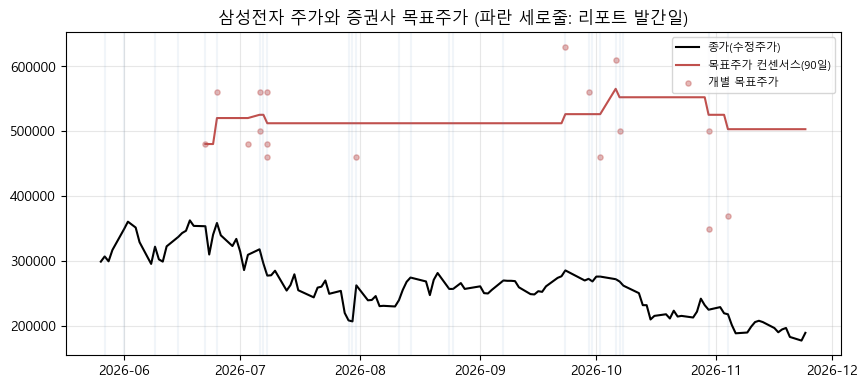

In [8]:
def consensus(day, window=90):
    w = tp[(tp["date"] <= day) & (tp["date"] > day - pd.Timedelta(days=window))]
    return w.groupby("name_ko").tail(1)["target_price"].mean() if len(w) else None

cons = pd.Series({d: consensus(d) for d in px.index})
last_day = px.index[-1]
for w in (90, 30):
    c = consensus(last_day, w)
    print(f"{last_day.date()} 종가 {px.iloc[-1]:,.0f}원 | 최근 {w}일 목표주가 컨센서스 "
          + (f"{c:,.0f}원 | 괴리(상승여력) {(c / px.iloc[-1] - 1) * 100:+.1f}%" if c else "없음"))
print("※ 주가가 급락한 뒤엔 예전 목표가가 남아 있어 90일 컨센서스의 괴리가 크게 나옵니다. 최근 30일 값과 같이 보세요.")

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(px.index, px.values, color="k", label="종가(수정주가)")
ax.plot(cons.index, cons.values, color="#c0504d", label="목표주가 컨센서스(90일)")
ax.scatter(tp["date"], tp["target_price"], s=14, color="#c0504d", alpha=.4, label="개별 목표주가")
for d in rep["created_at"].dt.normalize().unique():
    ax.axvline(d, color="#4f81bd", alpha=.08)
ax.set_title(f"{name} 주가와 증권사 목표주가 (파란 세로줄: 리포트 발간일)"); ax.legend(fontsize=8); ax.grid(alpha=.3)

## 3. 최신 리포트 PDF 첫 장 읽기
리포트 링크는 공개 CDN의 PDF입니다. 첫 페이지 텍스트에서 투자의견·목표주가 줄을 찾아 보여줍니다.

In [9]:
pdf_doc = rep[rep["url"].str.endswith(".pdf", na=False)].iloc[0]
print(pdf_doc["created_at"].date(), pdf_doc["publisher"], "|", pdf_doc["title"])
pdf = fitz.open(stream=requests.get(pdf_doc["url"], timeout=60).content, filetype="pdf")
first = pdf[0].get_text()
print(f"총 {pdf.page_count}쪽, 첫 장 {len(first):,}자\n")
for line in first.splitlines():
    if re.search(r"목표주가|투자의견|Target|BUY|매수|Rating", line, re.I):
        print("  ▶", line.strip()[:100])
print("\n--- 첫 장 앞부분 ---\n" + re.sub(r"\n{2,}", "\n", first)[:900])

2026-11-04 iM증권 | STRESS TEST


총 12쪽, 첫 장 2,626자

  ▶ 목표주가 37만원, ‘28년 기준으로는 56만원까지 열림
  ▶ 투자의견 Buy, 목표주가 37만원으로 커버리지를 개시한다. ‘27년 BPS에 목표
  ▶ 이 경우 ‘28년 BPS 기준 목표주가는 56만원까지 열릴 수 있다[표2].
  ▶ Buy (Initiation)
  ▶ 목표주가(12M)

--- 첫 장 앞부분 ---
 
 
 
 
반도체(Overweight): Stress Test 
78 
삼성전자  (005930) 
2026.11.04 
 
STRESS TEST 
[반도체/전기전자] 고의영 
2122-9179 ey.ko@imfnsec.com 
 
 
 
목표주가 37만원, ‘28년 기준으로는 56만원까지 열림 
투자의견 Buy, 목표주가 37만원으로 커버리지를 개시한다. ‘27년 BPS에 목표 
P/B 2.3배를 적용했다. 이는 ‘00년 이후 25년간 평균 P/B의 +2표준편차에 
해당한다[표1]. ‘26~’28년 ROE는 각각 56%, 59%, 48%로 지난 25년 평균인 
22%를 크게 상회할 전망이며, 고원형 ROE가 장기간 유지될 것으로 판단한다.  
이익 지속성에 대한 믿음이 공고해질 경우 시장의 시야는 ‘28년으로 향할 것이다. 
이 경우 ‘28년 BPS 기준 목표주가는 56만원까지 열릴 수 있다[표2]. 
동사 주가는 ‘26년 6월 고점 대비 10월 저점 기준 43% 하락해 과거 다운사이클 
평균 하락폭인 -41%를 넘어섰다. 특히 과거 8~13개월에 걸쳐 진행됐던 조정이 
이번에는 4개월 만에 나타났다. 시장이 ‘28년 이익 급감을 상정하고 있는 것이다. 
이러한 우려가 지속되는 한, 이익의 눈높이가 높아질수록 멀티플은 저렴해질 
뿐이며, DRAM 가격이 예상보다 더 올라갈 것이라는 소식이 주가의 촉매로 
작용하지 못한다. 결국 주가 반등을 위해서는 시장이 상정하고 있는 다운사이클이 
우려만큼 깊지 않을 것이라는 믿음이 필요한 것으로 본다. 
 
STRESS TEST와 HBM 재평가 
① 당사는 

## 4. 요즘 리포트가 가장 많이 나온 종목
최근 4주 기업 리포트를 종목 코드로 집계합니다. 리포트가 몰리는 종목은 실적 발표·이벤트로 시장의 관심이 큰 종목입니다.

In [10]:
agg = ds_df(f'DocumentAggregation(["research"],["company"],"*","securities.symbol:30",'
            f'date_from={(pd.Timestamp(ASOF) - pd.Timedelta(days=28)).date()},date_to={ASOF})')
agg = agg[agg["key"].astype(str).str.len() == 6]          # 종목 태그가 없는 리포트("" 키)는 뺀다
agg["symbol"] = "KRX:" + agg["key"].astype(str)
top = agg.merge(universe()[["symbol", "name", "market"]], on="symbol", how="left")
snap = all_stocks(ASOF, common_only=False)[["symbol", "change_pct", "market_cap"]]
top = top.merge(snap, on="symbol", how="left")
top["시가총액"] = top["market_cap"].map(krw)
top[["name", "market", "count", "시가총액", "change_pct"]].rename(
    columns={"name": "종목", "count": "리포트 수(4주)", "change_pct": f"{ASOF} 등락률(%)"}).head(15).round(2)

,종목,market,리포트 수(4주),시가총액,2026-11-24 등락률(%)
0,기아,KOSPI,12,37.3조,10.65
1,삼성전기,KOSPI,11,64.1조,10.28
2,한화에어로스페이스,KOSPI,11,32.4조,9.22
3,현대차,KOSPI,10,56.0조,11.11
4,삼성SDI,KOSPI,10,36.3조,13.64
5,현대글로비스,KOSPI,10,15.5조,8.57
6,코스맥스,KOSPI,10,3.3조,2.28
7,파마리서치,KOSDAQ,10,2.7조,-3.29
8,SK텔레콤,KOSPI,9,14.4조,4.02
9,NAVER,KOSPI,9,23.7조,4.07


## 결과 읽는 법과 한계
- DeepSearch 리서치는 **약 15개 증권사**(삼성·신한·한국투자·미래에셋·iM·SK·LS·유진·대신·메리츠·한화·IBK·유안타·상상인·한국IR협의회) 리포트입니다. KB·NH·키움 등은 없어 **전체 컨센서스보다 표본이 작습니다.**
- 목표주가 컨센서스는 이 노트북이 직접 계산한 값(증권사별 최근 90일 최신값 평균)이라 다른 정보업체 컨센서스와 다를 수 있습니다.
- 같은 리포트가 두 번 들어온 경우가 있어 증권사·제목으로 중복을 지웠습니다.
- PDF 첫 장은 증권사마다 배치가 달라 투자의견·목표주가 줄을 못 찾을 수도 있습니다. 숫자는 `SearchTargetPrices` 값을 기준으로 보세요.
- `SearchAnalystReports` 함수는 이 구독에서 오류(500) 또는 0행이라 쓰지 않습니다.